# What thousands of headline experiments say about A/B testing
## Part 2 of 2: confirmation

The exploratory notebook made predictions from 4,873 tests. This notebook tests them on the 22,743 tests
of the confirmatory file, following `analysis_plan.md`, which was committed before this notebook was run.
Nothing here was tuned after seeing these results.

This notebook is generated from `02_confirmatory.py` by `scripts/build_notebooks.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "abtests.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import abtests as ab  # noqa: E402
import charts  # noqa: E402

RESULTS, FIGURES = ROOT / "results", ROOT / "figures"
pd.set_option("display.width", 170, "display.max_columns", 20, "display.max_colwidth", 95,
              "display.float_format", "{:,.3f}".format)

data = ab.load(ROOT / "data" / "raw" / "upworthy-archive-confirmatory-packages-03.12.2020.csv")
tests = ab.test_table(data).join(ab.what_varies(data))
print(f"{len(data):,} packages in {len(tests):,} tests")

105,549 packages in 22,741 tests


## A. Do the figures for the tests as a whole replicate?

Each prediction replicates if the confirmatory figure is within the difference allowed in the plan.

In [2]:
predictions = pd.read_csv(RESULTS / "predictions.csv", index_col="measure")
confirmatory = ab.summary(data)
replication = predictions.assign(confirmatory=confirmatory.reindex(predictions.index))
replication["difference"] = replication["confirmatory"] - replication["exploratory"]
replication["replicated"] = replication["difference"].abs() <= replication["allowed_difference"]
replication.to_csv(RESULTS / "replication.csv")
confirmatory.rename("confirmatory").to_csv(RESULTS / "confirmatory_summary.csv", header=True, index_label="measure")
display(replication)
print(f"{int(replication['replicated'].sum())} of {len(replication)} predictions replicated")

,exploratory,allowed_difference,confirmatory,difference,replicated
measure,,,,,
"Tests with an uneven traffic split, %",15.452,3.000,15.523,0.070,True
"Tests significant at 0.05, %",45.320,3.000,45.585,0.266,True
"Tests significant with the false discovery rate held at 5%, %",35.299,3.000,36.477,1.178,True
"Tests estimated to hold a real difference, %",64.412,4.000,64.902,0.490,True
"Headline-only tests significant at 0.05, %",55.618,4.000,54.310,-1.308,True
"Image-only tests significant at 0.05, %",42.988,4.000,44.354,1.366,True
"Teaser-text-only tests significant at 0.05, %",23.293,4.000,22.793,-0.500,True
True spread of click rates within a test (SD of log odds),0.244,0.020,0.253,0.009,True
"Measured lift of the best package over the test average, median %",29.919,3.000,30.153,0.235,True


12 of 12 predictions replicated


## B. The seven hypotheses about headlines

In [3]:
explored = pd.read_csv(RESULTS / "exploratory_headline_model.csv", index_col="feature")
headline_tests = tests.index[tests["varies"] == "headline only"]
pure = data[data["test"].isin(headline_tests)].reset_index(drop=True)
fit = ab.within_test_model(pure, ab.headline_features(pure["headline"]))
print(f"{len(headline_tests):,} tests that vary only the headline, {len(pure):,} headlines")

result = pd.DataFrame({"property": explored["property"], "hypothesis": explored["hypothesis"],
                       "predicted": np.where(explored["beta"] > 0, "more clicks", "fewer clicks"),
                       "exploratory_ratio": explored["ratio"], "exploratory_low": explored["low"],
                       "exploratory_high": explored["high"], "confirmatory_ratio": fit["ratio"],
                       "confirmatory_low": fit["low"], "confirmatory_high": fit["high"], "p_value": fit["p_value"]})
hypotheses = result[result["hypothesis"]].copy()
hypotheses["holm_p"] = ab.holm(hypotheses["p_value"])
hypotheses["same_direction"] = (hypotheses["confirmatory_ratio"] > 1) == (hypotheses["exploratory_ratio"] > 1)
hypotheses["confirmed"] = hypotheses["same_direction"] & (hypotheses["holm_p"] < 0.05)
result = result.join(hypotheses[["holm_p", "same_direction", "confirmed"]])
result.loc[~result["hypothesis"], "predicted"] = "no prediction"
result.to_csv(RESULTS / "confirmatory_headline_model.csv", index_label="feature")
confirmed = int(hypotheses["confirmed"].sum())
display(hypotheses[["property", "predicted", "exploratory_ratio", "confirmatory_ratio", "confirmatory_low",
                    "confirmatory_high", "holm_p", "confirmed"]].sort_values("holm_p"))
print(f"{confirmed} of {len(hypotheses)} hypotheses confirmed")

8,669 tests that vary only the headline, 39,927 headlines


,property,predicted,exploratory_ratio,confirmatory_ratio,confirmatory_low,confirmatory_high,holm_p,confirmed
question,Has a question mark,fewer clicks,0.902,0.911,0.900,0.922,0.000,True
words_per_5,Five more words,more clicks,1.068,1.056,1.047,1.065,0.000,True
points_forward,"Points forward (this, these, here's)",more clicks,1.045,1.061,1.050,1.073,0.000,True
number,Contains a number,more clicks,1.063,1.058,1.042,1.075,0.000,True
first_person_plural,"Says we, our or us",fewer clicks,0.919,0.945,0.929,0.960,0.000,True
colon,Has a colon,fewer clicks,0.927,0.931,0.911,0.952,0.000,True
exclamation,Has an exclamation mark,fewer clicks,0.895,0.939,0.912,0.966,0.000,True


7 of 7 hypotheses confirmed


The five properties that carried no prediction:

In [4]:
display(result.loc[~result["hypothesis"], ["property", "exploratory_ratio", "confirmatory_ratio", "confirmatory_low",
                                           "confirmatory_high", "p_value"]])

,property,exploratory_ratio,confirmatory_ratio,confirmatory_low,confirmatory_high,p_value
first_person_singular,"Says I, my or me",1.037,1.033,1.018,1.048,0.000
second_person,"Speaks to the reader (you, your)",1.011,0.994,0.983,1.006,0.335
quotation,Has a quotation,0.974,0.953,0.912,0.995,0.030
starts_with_number,Starts with a number,1.008,1.011,0.981,1.042,0.471
emphasis,Shouts (a word in capitals or *stars*),0.977,0.978,0.961,0.996,0.018


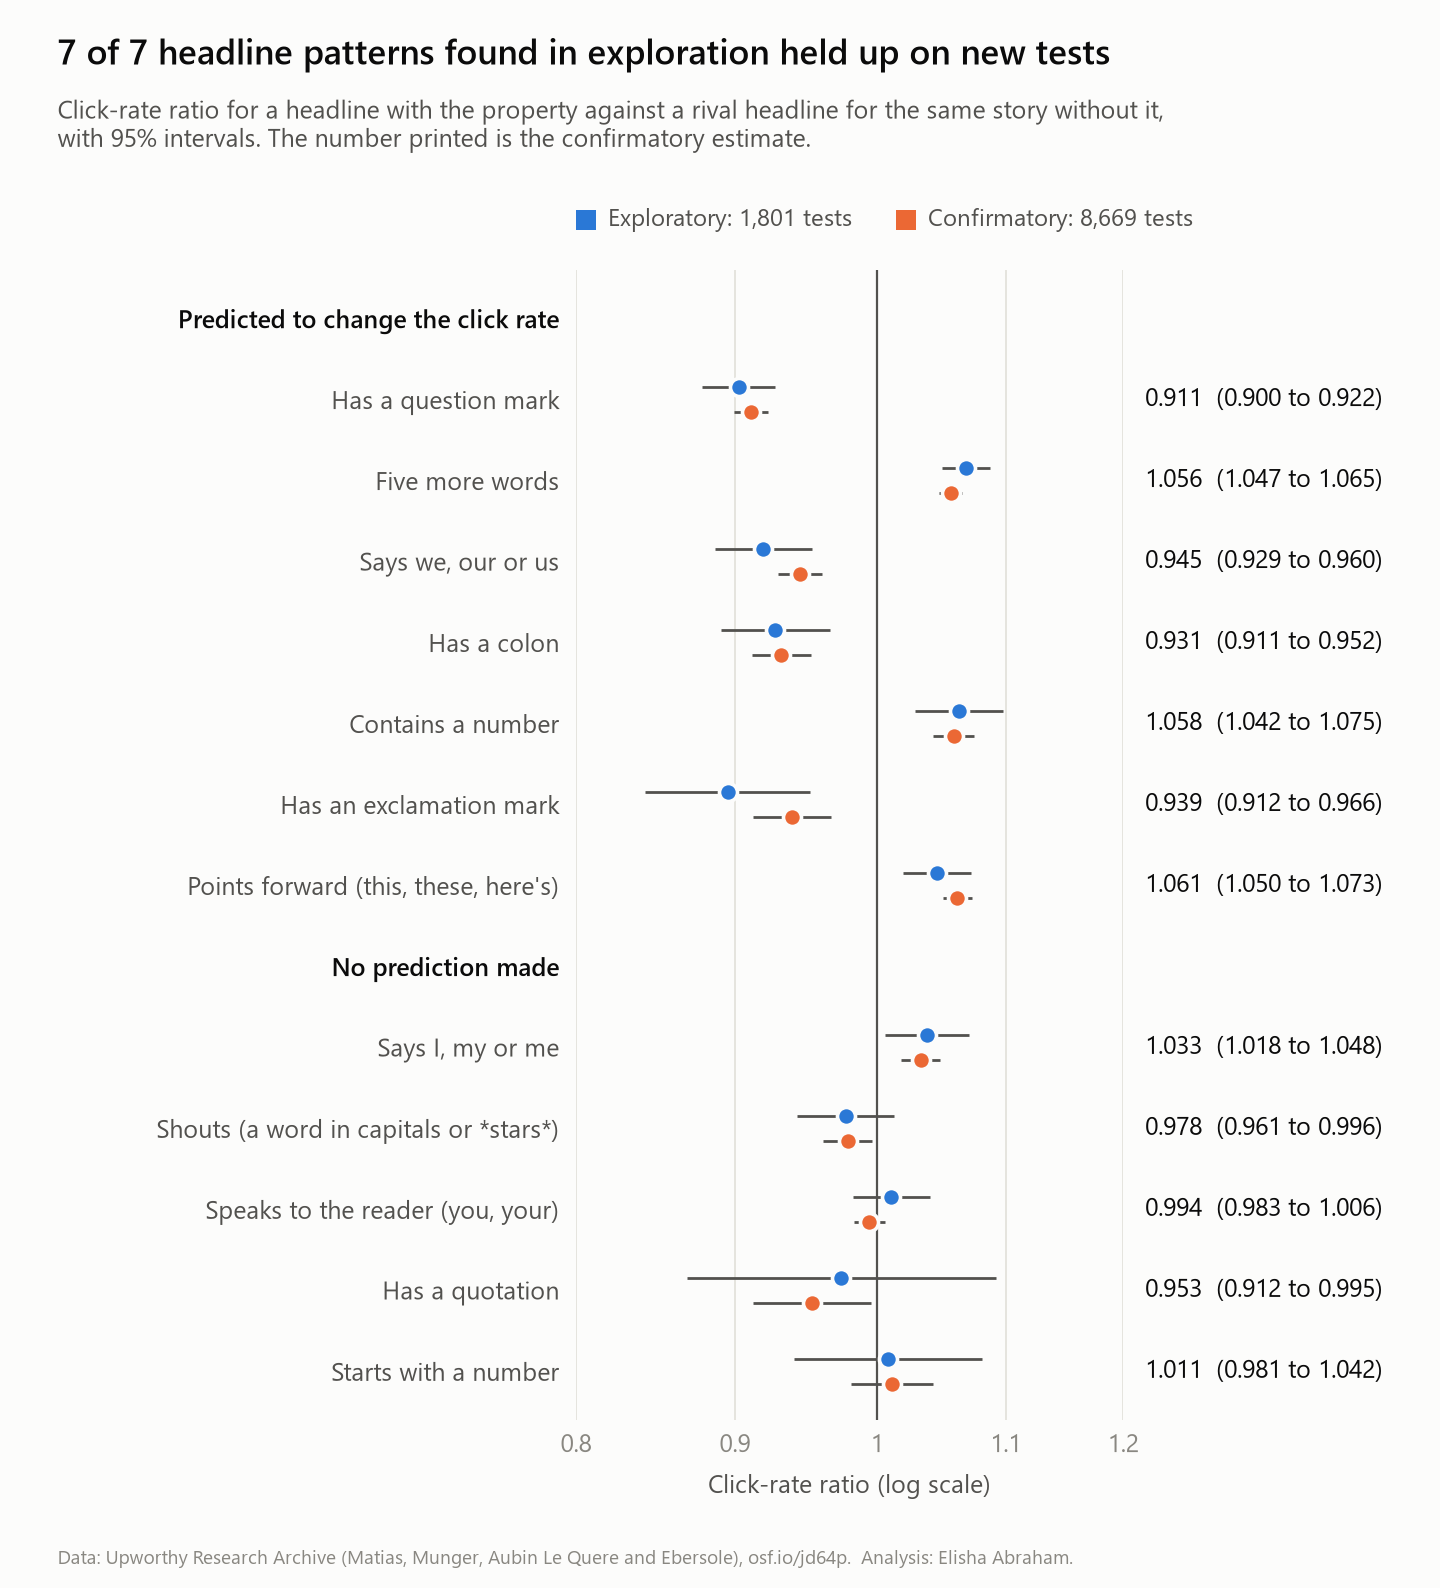

In [5]:
def row(feature: str) -> dict:
    values = result.loc[feature]
    return {"label": values["property"],
            "first": (values["exploratory_ratio"], values["exploratory_low"], values["exploratory_high"]),
            "second": (values["confirmatory_ratio"], values["confirmatory_low"], values["confirmatory_high"])}


strongest_first = explored["z"].abs().sort_values(ascending=False).index
rows = ([{"label": "Predicted to change the click rate"}] + [row(f) for f in strongest_first if result.loc[f, "hypothesis"]]
        + [{"label": "No prediction made"}] + [row(f) for f in strongest_first if not result.loc[f, "hypothesis"]])
charts.paired_forest(rows, (f"Exploratory: {int(explored['tests'].iloc[0]):,} tests", f"Confirmatory: {len(headline_tests):,} tests"),
                     f"{confirmed} of {len(hypotheses)} headline patterns found in exploration held up on new tests",
                     "Click-rate ratio for a headline with the property against a rival headline for the same story without it,\n"
                     "with 95% intervals. The number printed is the confirmatory estimate.",
                     FIGURES, "04_headline_patterns", [0.8, 0.9, 1.0, 1.1, 1.2], "Click-rate ratio (log scale)")
display(Image(filename=str(FIGURES / "04_headline_patterns_light.png"), width=720))

## C. Did the effects shrink, as predicted?

The plan predicted that effects chosen for being large in exploration would be closer to 1 on new data.

In [6]:
size_before = np.log(hypotheses["exploratory_ratio"]).abs()
size_after = np.log(hypotheses["confirmatory_ratio"]).abs() * np.where(hypotheses["same_direction"], 1, -1)
print(f"average size of the seven effects in exploration:  {100 * (np.exp(size_before.mean()) - 1):.1f}%")
print(f"average size of the same effects in confirmation: {100 * (np.exp(size_after.mean()) - 1):.1f}%")
print(f"effects smaller in confirmation: {int((size_after < size_before).sum())} of {len(hypotheses)}")
pd.DataFrame({"property": hypotheses["property"], "exploratory_size_%": 100 * (np.exp(size_before) - 1),
              "confirmatory_size_%": 100 * (np.exp(size_after) - 1)}).to_csv(RESULTS / "effect_shrinkage.csv", index_label="feature")

average size of the seven effects in exploration:  8.1%
average size of the same effects in confirmation: 6.7%
effects smaller in confirmation: 6 of 7
